# PS-02: Retail Customer Purchase Prediction — Dataset Adaptation

**Dataset:** `PS02_Retail_Customer_Purchase_Prediction(1).csv`

## Important data limitation
The supplied file contains 5,000 completed sales and the existing `Purchase` column contains only `1`. It has no website-session fields (pages viewed, time on site, cart activity) and no non-purchase examples. Therefore, a genuine purchase/no-purchase classifier cannot be trained or evaluated from this dataset as-is.

To make a runnable classification exercise from the available data, this notebook creates a clearly labeled **proxy target**: `High_Sales_Order = 1` when an order's `Sales` is at or above the dataset median, otherwise `0`. This predicts high-value vs. lower-value orders, **not whether a visitor will purchase**.

No model can honestly be guaranteed to achieve 99% accuracy. The notebook reports measured test-set metrics instead.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

## 2. Load the CSV

In [2]:
# Keep the CSV in the same folder as this notebook.
DATA_PATH = "PS02_Retail_Customer_Purchase_Prediction(1).csv"
df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())
print("\\nColumns:")
print(df.columns.tolist())

Shape: (5000, 15)


,Order ID,Order Date,Customer Name,Region,City,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Sales,Profit,Payment Mode,Purchase
0,10001,2024-10-19,Kashvi Varty,South,Bangalore,Books,Non-Fiction,Non-Fiction Ipsum,2,36294,5,68958.6,10525.09,Debit Card,1
1,10002,2025-08-30,Advik Desai,North,Delhi,Groceries,Rice,Rice Nemo,1,42165,20,33732.0,6299.66,Debit Card,1
2,10003,2023-11-04,Rhea Kalla,East,Patna,Kitchen,Juicer,Juicer Odio,4,64876,20,207603.2,19850.27,Credit Card,1
3,10004,2025-05-23,Anika Sen,East,Kolkata,Groceries,Oil,Oil Doloribus,5,37320,15,158610.0,36311.02,UPI,1
4,10005,2025-01-19,Akarsh Kaul,West,Pune,Clothing,Kids Wear,Kids Wear Quo,1,50037,10,45033.3,9050.04,Debit Card,1


\nColumns:
['Order ID', 'Order Date', 'Customer Name', 'Region', 'City', 'Category', 'Sub-Category', 'Product Name', 'Quantity', 'Unit Price', 'Discount', 'Sales', 'Profit', 'Payment Mode', 'Purchase']


## 3. Check data quality and target availability

In [3]:
display(df.info())
print("Missing values per column:")
display(df.isna().sum().sort_values(ascending=False))
print("Existing Purchase target distribution:")
display(df["Purchase"].value_counts(dropna=False) if "Purchase" in df.columns else "No Purchase column")

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       5000 non-null   int64  
 1   Order Date     5000 non-null   str    
 2   Customer Name  5000 non-null   str    
 3   Region         5000 non-null   str    
 4   City           5000 non-null   str    
 5   Category       5000 non-null   str    
 6   Sub-Category   5000 non-null   str    
 7   Product Name   5000 non-null   str    
 8   Quantity       5000 non-null   int64  
 9   Unit Price     5000 non-null   int64  
 10  Discount       5000 non-null   int64  
 11  Sales          5000 non-null   float64
 12  Profit         5000 non-null   float64
 13  Payment Mode   5000 non-null   str    
 14  Purchase       5000 non-null   int64  
dtypes: float64(2), int64(5), str(8)
memory usage: 938.9 KB


None

Missing values per column:


Order ID         0
Order Date       0
Customer Name    0
Region           0
City             0
Category         0
Sub-Category     0
Product Name     0
Quantity         0
Unit Price       0
Discount         0
Sales            0
Profit           0
Payment Mode     0
Purchase         0
dtype: int64

Existing Purchase target distribution:


Purchase
1    5000
Name: count, dtype: int64

## 4. Create the proxy classification target

`Sales` is used only to define the target, then removed from the input features. `Profit` is also removed because it is closely related to sales and could leak outcome information.

In [4]:
if "Sales" not in df.columns:
    raise ValueError("Expected a 'Sales' column in the supplied dataset.")

sales_median = df["Sales"].median()
df["High_Sales_Order"] = (df["Sales"] >= sales_median).astype(int)

print(f"Sales median threshold: {sales_median:,.2f}")
print("Proxy target counts:")
display(df["High_Sales_Order"].value_counts().rename(index={0: "Lower-sales order (0)", 1: "High-sales order (1)"}))

Sales median threshold: 83,080.32
Proxy target counts:


High_Sales_Order
Lower-sales order (0)    2500
High-sales order (1)     2500
Name: count, dtype: int64

## 5. Prepare features and split data

In [5]:
# Remove identifiers, original target, and columns that would leak the target.
drop_cols = ["High_Sales_Order", "Sales", "Profit", "Purchase", "Order ID", "Customer Name", "Order Date"]
X = df.drop(columns=[c for c in drop_cols if c in df.columns], errors="ignore")
y = df["High_Sales_Order"]

# Drop rows where the target is missing (normally none for this dataset).
valid = y.notna()
X, y = X.loc[valid].copy(), y.loc[valid].astype(int)

categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Input features:", X.columns.tolist())

Training rows: 4000
Test rows: 1000
Input features: ['Region', 'City', 'Category', 'Sub-Category', 'Product Name', 'Quantity', 'Unit Price', 'Discount', 'Payment Mode']


## 6. Train and compare two classification algorithms

In [6]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, random_state=42,
        class_weight="balanced", n_jobs=-1
    )
}

fitted_models = {}
results = []

for name, model in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else None

    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba) if proba is not None and y_test.nunique() == 2 else np.nan
    }
    results.append(row)
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
display(results_df.style.format({
    "Accuracy": "{:.3f}", "Precision": "{:.3f}", "Recall": "{:.3f}",
    "F1-score": "{:.3f}", "ROC-AUC": "{:.3f}"
}))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
1,Random Forest,0.909,0.871,0.960,0.913,0.966
0,Logistic Regression,0.885,0.892,0.876,0.884,0.974


## 7. Evaluate the best model

Selected model: Random Forest
\nClassification report:
                   precision    recall  f1-score   support

Lower-sales order       0.96      0.86      0.90       500
 High-sales order       0.87      0.96      0.91       500

         accuracy                           0.91      1000
        macro avg       0.91      0.91      0.91      1000
     weighted avg       0.91      0.91      0.91      1000



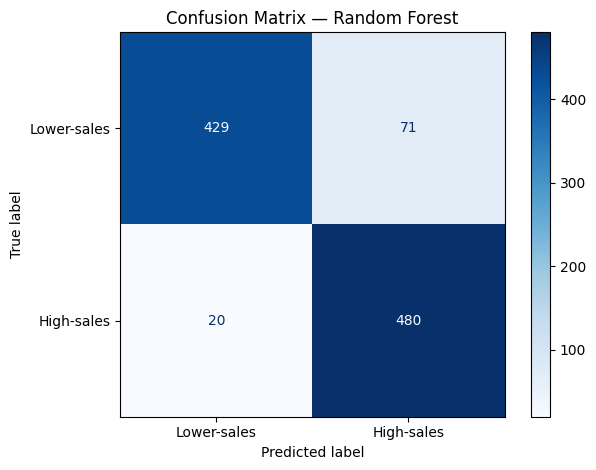

In [7]:
best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("Selected model:", best_name)
print("\\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["Lower-sales order", "High-sales order"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Lower-sales", "High-sales"], cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

## 8. Predict for a new order

In [8]:
# Example: use a row from the held-out test set as a demonstration.
# Replace this example row with feature values for a new order.
new_order = X_test.iloc[[0]].copy()
predicted_class = int(best_model.predict(new_order)[0])
purchase_like_probability = float(best_model.predict_proba(new_order)[0, 1])

print("Input example:")
display(new_order)
print("Predicted class:", "High-sales order" if predicted_class == 1 else "Lower-sales order")
print(f"Estimated probability of high-sales order: {purchase_like_probability:.1%}")

Input example:


,Region,City,Category,Sub-Category,Product Name,Quantity,Unit Price,Discount,Payment Mode
2492,North,Lucknow,Books,Non-Fiction,Non-Fiction Modi,4,7300,15,Net Banking


Predicted class: Lower-sales order
Estimated probability of high-sales order: 39.2%


## 9. Save the trained model (optional)

In [9]:
import joblib
MODEL_PATH = "ps02_high_sales_order_model.joblib"
joblib.dump(best_model, MODEL_PATH)
print("Saved model to:", MODEL_PATH)

Saved model to: ps02_high_sales_order_model.joblib


## Conclusion and interpretation

- This notebook compares Logistic Regression and Random Forest and reports accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.
- The notebook does **not** promise 99% accuracy; use the measured test metrics.
- The current target is a **high-sales-order proxy**, not actual purchase behavior.
- To meet the original PS-02 problem statement, obtain session-level data with features such as pages viewed, time spent, previous visits, products viewed, cart activity, device type, previous purchases, and a real binary `Purchase` label containing both `0` and `1`.